# Q10 — Particle Swarm Optimisation for the Rosenbrock Function

Particle Swarm Optimisation (PSO) searches for the minimum of the two-dimensional Rosenbrock function. Each particle updates its velocity using inertia, its own best position and the swarm's best position.

## 1. Objective function

The function is \(f(x,y)=(1-x)^2+100(y-x^2)^2\). Its global minimum is \((1,1)\), where the function value is zero. The search is restricted to \([-3,3]^2\).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(7)
def rosenbrock(position):
    x, y = position[..., 0], position[..., 1]
    return (1-x)**2 + 100*(y-x**2)**2

print('Known minimum: (1, 1), f(1,1) =', rosenbrock(np.array([1.0,1.0])))

Known minimum: (1, 1), f(1,1) = 0.0

## 2. Initialise the swarm

Positions are sampled uniformly from the search box and velocities start small. Each particle stores its personal-best location; the best personal-best across the swarm is the global best.

In [1]:
n_particles, dimensions = 40, 2
lower, upper = -3.0, 3.0
position = np.random.uniform(lower, upper, (n_particles, dimensions))
velocity = np.random.uniform(-0.5, 0.5, (n_particles, dimensions))
personal_best = position.copy()
pbest_value = rosenbrock(position)
g = int(np.argmin(pbest_value))
global_best = personal_best[g].copy()
gbest_value = float(pbest_value[g])
history = [gbest_value]
print(f"Particles: {n_particles}; bounds: [{lower}, {upper}] per dimension")
print(f"Initial best fitness: {gbest_value:.6f}")

Particles: 40; bounds: [-3.0, 3.0] per dimension
Initial best fitness: 26.318423

## 3. Update velocity and position

The inertia weight decreases from 0.9 to 0.4. Cognitive and social coefficients are both 1.7. Velocities are clipped to \([-1,1]\), and positions are kept inside the search bounds.

In [1]:
iterations = 200
c1 = c2 = 1.7
for iteration in range(iterations):
    inertia = 0.9 - (0.9-0.4)*iteration/(iterations-1)
    r1 = np.random.rand(n_particles, dimensions)
    r2 = np.random.rand(n_particles, dimensions)
    velocity = (inertia*velocity + c1*r1*(personal_best-position)
                + c2*r2*(global_best-position))
    velocity = np.clip(velocity, -1, 1)
    position = np.clip(position + velocity, lower, upper)
    values = rosenbrock(position)
    improved = values < pbest_value
    personal_best[improved] = position[improved]
    pbest_value[improved] = values[improved]
    g = int(np.argmin(pbest_value))
    if pbest_value[g] < gbest_value:
        gbest_value = float(pbest_value[g])
        global_best = personal_best[g].copy()
    history.append(gbest_value)

print(f"Initial best fitness: {history[0]:.6f}")
for i in [1,10,25,50,100,150,200]:
    print(f"Iter {i:3d}: {history[i]:.10g}")
print(f"Best position: x = {global_best[0]:.8f}, y = {global_best[1]:.8f}")
print(f"Rosenbrock value: {gbest_value:.10g}")
print("Known global minimum: (1, 1), f(1,1) = 0")

Initial best fitness: 26.318423
Iter   1: 0.4578586761
Iter  10: 0.0037524688
Iter  25: 0.0037524688
Iter  50: 0.0001513524
Iter 100: 0.0000207406
Iter 150: 0.0000000048
Iter 200: 0.000000000006
Best position: x = 1.00000216, y = 1.00000444
Rosenbrock value: 6.120716887e-12
Known global minimum: (1, 1), f(1,1) = 0

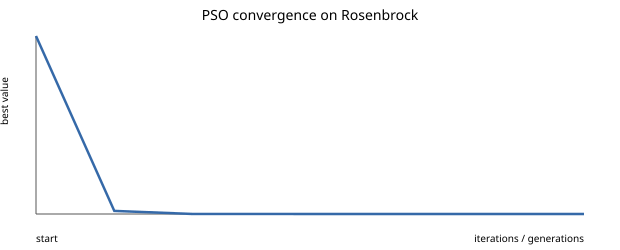

In [1]:
plt.figure(figsize=(8,4))
plt.semilogy(np.maximum(history, 1e-15))
plt.xlabel('Iteration')
plt.ylabel('Best function value (log scale)')
plt.title('PSO convergence on Rosenbrock function')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Result

The swarm converges close to **(1, 1)** and obtains a function value near zero. The result agrees with the known global minimum. Because PSO is stochastic, changing the seed or coefficients can change the convergence path.